# Module 3 Homework — Analytical Modeling (2026 cohort)

Homework: [homework3.md](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/cohorts/2026/homework3.md) · Base notebook: [[2026] Module 03 Colab — Time Series Modeling](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/03-modeling/%5B2026%5D_Module_03_Colab_Time_Series_Modeling.ipynb)

This notebook reproduces the data preparation of the course notebook step by step
(sections 0.1–0.4, 1.2 and 1.4.1), so the dataframe is the same one used in the lecture
and in grading. On top of it, it answers the homework questions:

| Question | What is computed |
|---|---|
| Q1 | Month × week-of-month dummies; highest absolute correlation with the target |
| Q2 | Two new macro "hand" rules (`pred3`, `pred4`); precision on TEST |
| Q3 | 10-level Decision Tree (`pred5_clf_10`); TEST records where only the tree is correct |
| Q4 | `max_depth` tuning (1–12) by TEST precision; best tree stored as `pred6_clf_best` |
| Q5 | Exploratory: what data is missing |

**Runtime:** several minutes on a standard Colab CPU, most of it the 12 tree fits in Q4.

**Implementation differences from the course notebook (the numbers are not affected):**
- the index is reset after filtering to 2000+, so every row has a unique label;
- correlations are computed only on the columns that are needed (pairwise Pearson values are identical, just faster);
- the temporal split uses `np.where` instead of a Python loop (same date boundaries);
- every Decision Tree uses `random_state=42`, as the homework requires.

## 0. Setup

In [8]:
%pip install -q gdown pyarrow matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [9]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

TARGET = "is_positive_growth_30d_future"

In [10]:
# The course dataset (33 large-cap stocks from the US, EU and India) is shared via Google Drive.
# It is ~144 MB, so it is downloaded at runtime and never committed to Git.
import gdown

DATA_FILE = "stocks_df_combined_2026_09_18.parquet.brotli"
DRIVE_FILE_ID = "1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5"  # same file as in the course notebook

if not os.path.exists(DATA_FILE):
    gdown.download(id=DRIVE_FILE_ID, output=DATA_FILE, quiet=False)

df_full = pd.read_parquet(DATA_FILE)
print(f"df_full: {df_full.shape[0]:,} rows x {df_full.shape[1]} columns (course: 240,759 x 203)")

Downloading...
From (original): https://drive.google.com/uc?id=1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5
From (redirected): https://drive.google.com/uc?id=1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5&confirm=t&uuid=bf80fd3a-8fca-49f2-a126-d2f9d630184b
To: /workspaces/stock-markets-analytics-zoomcamp-2026/03-modeling/stocks_df_combined_2026_09_18.parquet.brotli
100%|██████████| 144M/144M [00:02<00:00, 55.3MB/s] 


df_full: 240,759 rows x 203 columns (course: 240,759 x 203)


### 0.1 Variable sets (course section 0.1)

Copied from the course notebook so that the feature set is identical.

In [11]:
# Historical growth indicators (never the future ones)
GROWTH = [g for g in df_full.keys() if (g.find('growth_') == 0) & (g.find('future') < 0)]

OHLCV = ['Open', 'High', 'Low', 'Close', 'Adj Close_x', 'Volume']
CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type']
TO_PREDICT = [g for g in df_full.keys() if g.find('future') >= 0]
TO_DROP = ['Year', 'Date', 'index_x', 'index_y', 'index', 'Quarter', 'Adj Close_y'] + CATEGORICAL + OHLCV

# ln(Volume) with the course's guard against log(0)
df_full['ln_volume'] = np.log(df_full.Volume.replace(0, np.nan).fillna(1e-9))

# Manually defined features
CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative',
                    'volatility', 'ln_volume']

# TA-Lib indicators: https://github.com/TA-Lib/ta-lib-python/blob/master/docs/funcs.md
TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1', 'aroon_2', 'aroonosc',
    'bop', 'cci', 'cmo', 'dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
    'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
    'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
    'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
    'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
    'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
    'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
    'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

# Candlestick patterns
TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl') >= 0]

MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
         'DGS1', 'DGS5', 'DGS10']

NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

print(f"TO_PREDICT: {TO_PREDICT}")
print(f"Numerical features: {len(NUMERICAL)} (course: 184), candlestick patterns: {len(TECHNICAL_PATTERNS)} (course: 61)")

TO_PREDICT: ['growth_future_30d', 'is_positive_growth_30d_future']
Numerical features: 184 (course: 184), candlestick patterns: 61 (course: 61)


In [12]:
# ~25 years of data, exactly as in the course notebook
df = df_full[df_full.Date >= '2000-01-01'].copy()
df = df.reset_index(drop=True)  # unique row labels; values are unchanged

print(f"df: {len(df):,} rows (course: 202,292), tickers: {df.Ticker.nunique()} (course: 33), "
      f"dates {df.Date.min():%Y-%m-%d} .. {df.Date.max():%Y-%m-%d}")

df: 202,292 rows (course: 202,292), tickers: 33 (course: 33), dates 2000-01-03 .. 2026-09-18


## Q1 — Dummies for Month and Week-of-Month

**Question:** what is the absolute correlation of the most correlated `month_wom` dummy
with `is_positive_growth_30d_future` (3 decimals)?

Notes:
- Week of month = `(day - 1) // 7 + 1`, i.e. 7-day blocks of *calendar days*:
  days 1–7 → `w1`, 8–14 → `w2`, …, 29–31 → `w5` (always a short week).
- The course code below turns `Month` into the month *number* as a string (`'10'`),
  so the month *name* for `month_wom` is taken from `Date`.
- Expected: ~115 dummies in total, ~60 of them from `month_wom`. `February_w5` exists
  only in leap years where 29 February was a trading day.

In [13]:
# Course section 0.2: categorical columns as strings, so get_dummies() builds proper dummies
df['Weekday'] = df['Weekday'].astype(str)
df['Month'] = df['Month'].dt.month.astype(str)

In [14]:
# Q1: month name + week of month, e.g. 'October_w1'
week_of_month = (df['Date'].dt.day - 1) // 7 + 1
df['month_wom'] = df['Date'].dt.month_name() + '_w' + week_of_month.astype(str)

# Sanity check on one month: day -> label mapping
oct_2025 = df.loc[df.Date.between('2025-10-01', '2025-10-31'), ['Date', 'month_wom']].drop_duplicates()
print(oct_2025.groupby('month_wom')['Date'].agg(['min', 'max', 'count']))

                  min        max  count
month_wom                              
October_w1 2025-10-01 2025-10-07      5
October_w2 2025-10-08 2025-10-14      5
October_w3 2025-10-15 2025-10-21      5
October_w4 2025-10-22 2025-10-28      5
October_w5 2025-10-29 2025-10-31      3


In [15]:
CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type', 'month_wom']

# Generate dummy variables (int32 instead of bool, as in the course)
dummy_variables = pd.get_dummies(df[CATEGORICAL], dtype='int32')
DUMMIES = dummy_variables.keys().to_list()
MONTH_WOM_DUMMIES = [c for c in DUMMIES if c.startswith('month_wom_')]

print(f"Dummies in total: {len(DUMMIES)} (expected ~115), from month_wom: {len(MONTH_WOM_DUMMIES)} (expected ~60)")

df_with_dummies = pd.concat([df, dummy_variables], axis=1)

Dummies in total: 115 (expected ~115), from month_wom: 60 (expected ~60)


In [16]:
# Correlation of every month_wom dummy with the binary target (Pearson = phi coefficient here)
corr = df_with_dummies[MONTH_WOM_DUMMIES + [TARGET]].corr()[TARGET].drop(TARGET)

corr_df = corr.to_frame('corr')
corr_df['abs_corr'] = corr_df['corr'].abs()
corr_df['rows'] = df_with_dummies[MONTH_WOM_DUMMIES].sum()  # how many rows each dummy covers
corr_df = corr_df.sort_values('abs_corr', ascending=False)

corr_df.head(10)

,corr,abs_corr,rows
month_wom_October_w4,0.024584,0.024584,3831
month_wom_November_w3,0.023251,0.023251,3874
month_wom_February_w1,-0.020861,0.020861,4043
month_wom_January_w2,-0.019846,0.019846,3996
month_wom_January_w5,-0.019792,0.019792,1755
month_wom_November_w2,0.019103,0.019103,3846
month_wom_January_w3,-0.018537,0.018537,3538
month_wom_February_w2,-0.018340,0.018340,4007
month_wom_January_w4,-0.018265,0.018265,3912
month_wom_October_w3,0.017856,0.017856,3883


In [17]:
q1_dummy = corr_df.index[0]
q1_answer = corr_df['abs_corr'].iloc[0]

print(f"Most correlated month_wom dummy: {q1_dummy} (corr = {corr_df['corr'].iloc[0]:+.4f})")
print(f"Q1 answer: {q1_answer:.3f}")

Most correlated month_wom dummy: month_wom_October_w4 (corr = +0.0246)
Q1 answer: 0.025


For scale: a dummy that covers ~1/60 of the rows can reach at most |corr| ≈ 0.11 against a
target with a ~57–59% positive rate, even if it predicted growth perfectly. The `rows` column
shows how thin each dummy is; `February_w5` and other short `w5` weeks are the thinnest.

## Temporal split (course section 0.4)

~70% / 15% / 15% of the *date range*: train → validation → test.

In [18]:
def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15, test_prop=0.15):
    """Add a 'split' column ('train' / 'validation' / 'test') based on the 'Date' order."""
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)
    df['split'] = np.where(df['Date'] <= train_end, 'train',
                           np.where(df['Date'] <= val_end, 'validation', 'test'))
    return df


df_with_dummies = temporal_split(df_with_dummies,
                                 min_date=df_with_dummies.Date.min(),
                                 max_date=df_with_dummies.Date.max())

# defragment after many column operations (as in the course)
new_df = df_with_dummies.copy()

# Course run: train 2000-01-03..2018-09-13 (136,842), validation 2018-09-14..2022-09-15 (32,287),
#             test 2022-09-16..2026-09-18 (33,163)
new_df.groupby('split')['Date'].agg(['min', 'max', 'count'])

,min,max,count
split,,,
test,2022-09-16,2026-09-18,33163
train,2000-01-03,2018-09-13,136842
validation,2018-09-14,2022-09-15,32287


In [19]:
# Base rate per split = precision of the trivial rule "always predict 1"
print(new_df.groupby('split')[TARGET].mean().round(4))

# The last 30 trading days have no 30-day future yet (growth_future_30d is NaN).
# Check how the label is stored for them: NaN > 1 evaluates to False, i.e. label 0.
no_future = new_df['growth_future_30d'].isna()
print(f"\nRows without a 30-day future: {no_future.sum():,}, "
      f"label values there: {new_df.loc[no_future, TARGET].value_counts().to_dict()}, "
      f"latest such date: {new_df.loc[no_future, 'Date'].max():%Y-%m-%d}")

split
test          0.5701
train         0.5914
validation    0.6014
Name: is_positive_growth_30d_future, dtype: float64

Rows without a 30-day future: 990, label values there: {0: 990}, latest such date: 2026-09-18


If these rows carry label 0, every rule that fires in the last ~30 trading days of TEST is
penalised for growth that simply hasn't happened yet. We keep them, to stay consistent with
the course and the grading.

## Q2 — New "hand" rules on macro variables

**Question:** what is the precision on TEST of the best of the new rules (`pred3` / `pred4`), 3 decimals?

The course rules `pred0`–`pred2` (section 1.2) are reproduced first. All prediction columns start
with `pred`, so the `PREDICTIONS` / `IS_CORRECT` lists pick the new rules up automatically.

In [20]:
# Course section 1.2: manual "hand rule" predictions
new_df['pred0_manual_cci'] = (new_df.cci > 200).astype(int)
new_df['pred1_manual_prev_g1'] = (new_df.growth_30d > 1).astype(int)
new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)

# Q2: new rules from the positive branches of the 2026 tree (thresholds given in the homework)
new_df['pred3_manual_dgs10_5'] = ((new_df['DGS10'] <= 4.5) & (new_df['DGS5'] <= 4)).astype(int)
new_df['pred4_manual_dgs10_fedfunds'] = ((new_df['DGS10'] > 4) & (new_df['FEDFUNDS'] <= 4.795)).astype(int)

In [21]:
def refresh_prediction_columns(df, target=TARGET):
    """Course logic: list all 'pred*' columns and (re)build is_correct_predX for each of them."""
    predictions = [k for k in df.keys() if k.startswith('pred')]
    for pred in predictions:
        part1 = pred.split('_')[0]  # 'pred3_manual_dgs10_5' -> 'pred3'
        df[f'is_correct_{part1}'] = (df[pred] == df[target]).astype(int)
    is_correct = [k for k in df.keys() if k.startswith('is_correct_')]
    return predictions, is_correct


def precision_table(df, predictions, split='test', target=TARGET):
    """Precision of each 0/1 prediction on one split, next to the 'always predict 1' base rate.

    precision = share of correct predictions among rows where the prediction is 1 = TP / (TP + FP)
    """
    sub = df[df['split'] == split]
    base_rate = sub[target].mean()
    rows = []
    for pred in predictions:
        fired = sub[pred] == 1
        n_pos = int(fired.sum())
        precision = sub.loc[fired, f"is_correct_{pred.split('_')[0]}"].mean() if n_pos > 0 else np.nan
        rows.append({'prediction': pred,
                     'positive_preds': n_pos,
                     'coverage': n_pos / len(sub),
                     'precision': precision,
                     'lift_vs_base_pp': (precision - base_rate) * 100})
    print(f"{split.upper()}: {len(sub):,} rows, base rate (always predict 1) = {base_rate:.3f}")
    return pd.DataFrame(rows).set_index('prediction')


PREDICTIONS, IS_CORRECT = refresh_prediction_columns(new_df)
print(PREDICTIONS)
print(IS_CORRECT)

['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds']
['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4']


In [22]:
# Course run for reference: pred0 0.565, pred1 0.579, pred2 0.573
q2_table = precision_table(new_df, PREDICTIONS)
q2_table.round(4)

TEST: 33,163 rows, base rate (always predict 1) = 0.570


,positive_preds,coverage,precision,lift_vs_base_pp
prediction,,,,
pred0_manual_cci,921,0.0278,0.5646,-0.5489
pred1_manual_prev_g1,19158,0.5777,0.5787,0.8568
pred2_manual_prev_g1_and_snp,15244,0.4597,0.5726,0.2460
pred3_manual_dgs10_5,15910,0.4798,0.5877,1.7650
pred4_manual_dgs10_fedfunds,15921,0.4801,0.5025,-6.7549


In [23]:
NEW_RULES = ['pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds']
test_df = new_df[new_df.split == 'test']

# Cross-check with sklearn (zero_division=0: a rule without positive predictions gets 0)
for rule in NEW_RULES:
    n_pos = int(test_df[rule].sum())
    p = precision_score(test_df[TARGET], test_df[rule], zero_division=0)
    print(f"{rule}: {n_pos:,} positive predictions on TEST, sklearn precision = {p:.4f}")

best_new = q2_table.loc[NEW_RULES, 'precision'].dropna().sort_values(ascending=False)
q2_rule = best_new.index[0]
q2_answer = best_new.iloc[0]
print(f"\nQ2 answer: {q2_answer:.3f} ({q2_rule})")

pred3_manual_dgs10_5: 15,910 positive predictions on TEST, sklearn precision = 0.5877
pred4_manual_dgs10_fedfunds: 15,921 positive predictions on TEST, sklearn precision = 0.5025

Q2 answer: 0.588 (pred3_manual_dgs10_5)


In [24]:
# When do the macro rules fire? Macro values are the same for all tickers on a date,
# so these are market-timing signals: one decision per day, not per stock.
fire_by_year = test_df.groupby(test_df.Date.dt.year).agg(
    DGS10=('DGS10', 'mean'), DGS5=('DGS5', 'mean'), FEDFUNDS=('FEDFUNDS', 'mean'),
    pred3_share=('pred3_manual_dgs10_5', 'mean'),
    pred4_share=('pred4_manual_dgs10_fedfunds', 'mean'),
    base_rate=(TARGET, 'mean'))
fire_by_year.round(3)

,DGS10,DGS5,FEDFUNDS,pred3_share,pred4_share,base_rate
Date,,,,,,
2022,3.804,3.981,3.496,0.628,0.223,0.718
2023,3.964,4.063,5.028,0.468,0.008,0.661
2024,4.206,4.123,5.143,0.293,0.162,0.587
2025,4.293,3.920,4.212,0.672,0.975,0.555
2026,4.433,4.093,3.635,0.427,0.994,0.382


## Q3 — Unique correct predictions of a 10-level Decision Tree (`pred5_clf_10`)

**Question:** how many TEST records have `pred5_clf_10` correct while all hand rules `pred0`–`pred4` are wrong?

Data preparation follows course section 1.4.1 (`±inf → NaN → 0`), applied once to the whole
dataframe (`X_all`), so that train, test and "predict on everything" use the same cleaning.
The feature list now includes the new `month_wom` dummies from Q1.

In [25]:
features_list = NUMERICAL + DUMMIES

X_all = new_df[features_list].replace([np.inf, -np.inf], np.nan).fillna(0)
y_all = new_df[TARGET]

is_train_val = new_df.split.isin(['train', 'validation'])
is_test = new_df.split == 'test'

X_train, y_train = X_all[is_train_val], y_all[is_train_val]
X_test, y_test = X_all[is_test], y_all[is_test]

print(f"X_train {X_train.shape}, X_test {X_test.shape}  (course, before Q1 dummies: 169,129 / 33,163 rows)")

X_train (169129, 299), X_test (33163, 299)  (course, before Q1 dummies: 169,129 / 33,163 rows)


In [26]:
start = time.perf_counter()
clf_10 = DecisionTreeClassifier(max_depth=10, random_state=42)
clf_10.fit(X_train, y_train)
print(f"Fitted in {time.perf_counter() - start:.0f}s")

# Same rows, same order -> predictions can be assigned directly as a new column
new_df['pred5_clf_10'] = clf_10.predict(X_all)

y_pred_test = new_df.loc[is_test, 'pred5_clf_10']
print(f"TEST: accuracy = {accuracy_score(y_test, y_pred_test):.4f}, "
      f"precision = {precision_score(y_test, y_pred_test):.4f}, "
      f"positive predictions = {int(y_pred_test.sum()):,}")

Fitted in 18s
TEST: accuracy = 0.4774, precision = 0.5912, positive predictions = 8,628


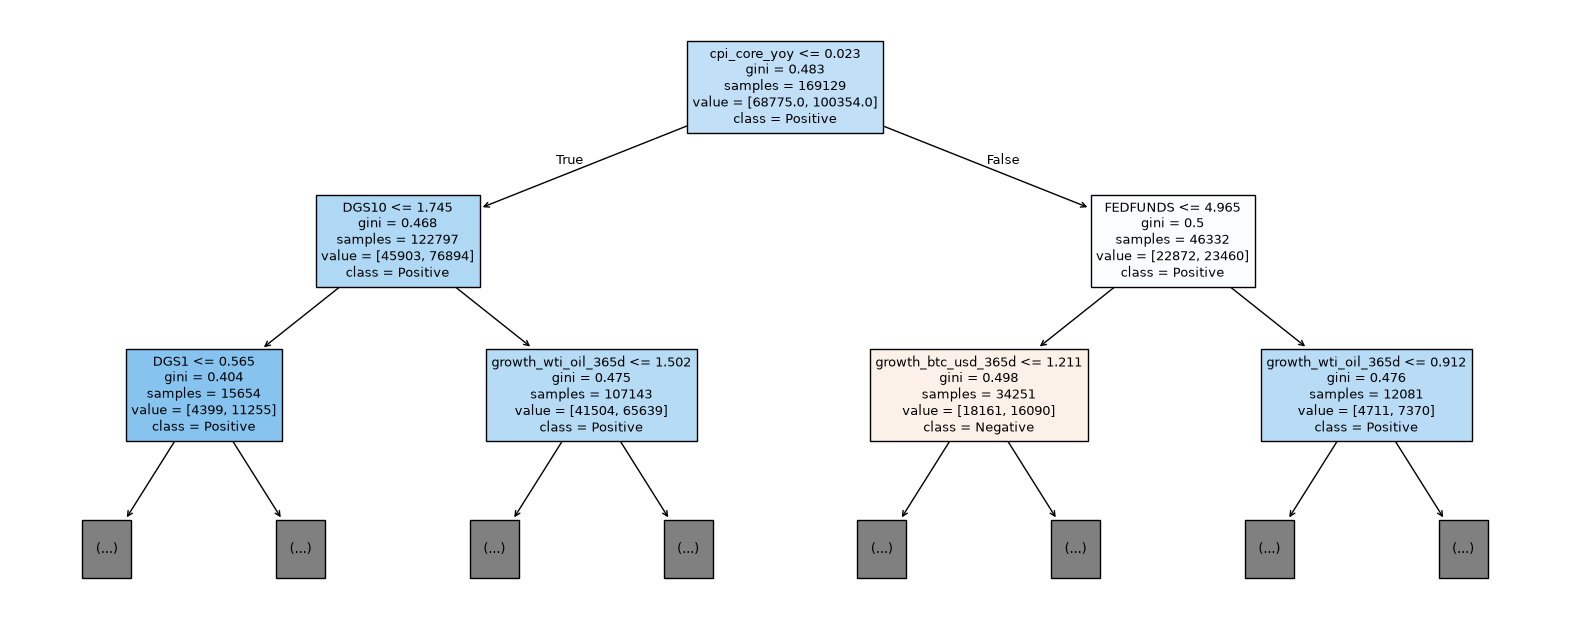

|--- cpi_core_yoy <= 0.02
|   |--- DGS10 <= 1.75
|   |   |--- DGS1 <= 0.56
|   |   |   |--- growth_snp500_90d <= 1.14
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- growth_snp500_90d >  1.14
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- DGS1 >  0.56
|   |   |   |--- growth_btc_usd_30d <= 1.07
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- growth_btc_usd_30d >  1.07
|   |   |   |   |--- truncated branch of depth 7
|   |--- DGS10 >  1.75
|   |   |--- growth_wti_oil_365d <= 1.50
|   |   |   |--- Month_7 <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- Month_7 >  0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- growth_wti_oil_365d >  1.50
|   |   |   |--- growth_wti_oil_30d <= 1.00
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- growth_wti_oil_30d >  1.00
|   |   |   |   |--- truncated branch of depth 7
|--- cpi_core_yoy >  0.02
|   |--- FEDFUNDS <= 4.96
|   |   |--- growth_bt

In [27]:
# Top levels of the 2026 tree: compare with the Q2 rules (DGS10 / DGS5 / FEDFUNDS)
plt.figure(figsize=(20, 8))
plot_tree(clf_10, filled=True, feature_names=list(X_train.columns),
          class_names=['Negative', 'Positive'], max_depth=2, fontsize=9)
plt.show()

print(export_text(clf_10, feature_names=list(X_train.columns), max_depth=3))

In [28]:
importances = (pd.Series(clf_10.feature_importances_, index=X_train.columns)
               .sort_values(ascending=False))
importances.head(15).round(4)

cpi_core_yoy           0.0662
growth_gold_365d       0.0520
cpi_core_mom           0.0462
growth_wti_oil_365d    0.0385
FEDFUNDS               0.0361
ad                     0.0350
obv                    0.0348
growth_dji_90d         0.0314
growth_btc_usd_365d    0.0306
trix                   0.0299
growth_snp500_365d     0.0278
DGS10                  0.0262
growth_snp500_90d      0.0252
DGS5                   0.0247
natr                   0.0216
dtype: float64

In [29]:
PREDICTIONS, IS_CORRECT = refresh_prediction_columns(new_df)
print(PREDICTIONS)

HAND_RULES_CORRECT = [f'is_correct_pred{i}' for i in range(5)]  # pred0 .. pred4

new_df['only_pred5_is_correct'] = (
    (new_df['is_correct_pred5'] == 1) & (new_df[HAND_RULES_CORRECT].sum(axis=1) == 0)
).astype(int)

q3_answer = int(new_df.loc[is_test, 'only_pred5_is_correct'].sum())
print(f"Q3 answer: {q3_answer:,} TEST records")

['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds', 'pred5_clf_10']
Q3 answer: 1,243 TEST records


In [30]:
# What kind of cases are they? 'Correct' is symmetric: a correct 0 counts as much as a correct 1.
unique_rows = new_df[is_test & (new_df['only_pred5_is_correct'] == 1)]
print(unique_rows['pred5_clf_10'].value_counts().rename('tree prediction'))

pred5_clf_10
1    1187
0      56
Name: tree prediction, dtype: int64


### Advanced: uniquely correct predictions for any prediction column

Vectorised instead of a row-wise `apply`: it gives the same result and runs in well under a
second on ~200k rows.

In [31]:
def uniquely_correct_counts(df, predictions, split='test'):
    """For each prediction: number of rows where it is the ONLY correct one among `predictions`."""
    sub = df[df['split'] == split]
    correct = sub[[f"is_correct_{p.split('_')[0]}" for p in predictions]]
    n_correct = correct.sum(axis=1)
    return pd.Series({p: int(((correct.iloc[:, i] == 1) & (n_correct == 1)).sum())
                      for i, p in enumerate(predictions)}, name='uniquely_correct')


unique_counts = uniquely_correct_counts(new_df, PREDICTIONS)
assert unique_counts['pred5_clf_10'] == q3_answer
unique_counts

pred0_manual_cci                 150
pred1_manual_prev_g1             380
pred2_manual_prev_g1_and_snp       2
pred3_manual_dgs10_5            1020
pred4_manual_dgs10_fedfunds     1550
pred5_clf_10                    1243
Name: uniquely_correct, dtype: int64

## Q4 — Hyperparameter tuning: `max_depth` from 1 to 12

**Question:** which `max_depth` gives the highest precision on TEST?

For each depth the tree is fitted on TRAIN+VALIDATION. Besides TEST precision the loop records:
- in-sample precision on TRAIN+VALIDATION — the gap to TEST shows overfitting;
- the number of positive predictions on TEST — precision based on very few signals is fragile.

In [32]:
results = []
models = {}

for depth in range(1, 13):
    start = time.perf_counter()
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf.fit(X_train, y_train)
    models[depth] = clf

    y_pred_test = clf.predict(X_test)
    y_pred_train = clf.predict(X_train)
    results.append({
        'max_depth': depth,
        'precision_test': precision_score(y_test, y_pred_test, zero_division=0),
        'precision_train_val': precision_score(y_train, y_pred_train, zero_division=0),
        'accuracy_test': accuracy_score(y_test, y_pred_test),
        'positive_preds_test': int(y_pred_test.sum()),
    })
    print(f"depth {depth:2d}: precision TEST = {results[-1]['precision_test']:.4f} "
          f"({time.perf_counter() - start:.0f}s)")

results = pd.DataFrame(results).set_index('max_depth')
results.round(4)

depth  1: precision TEST = 0.5701 (3s)
depth  2: precision TEST = 0.6225 (5s)
depth  3: precision TEST = 0.5720 (6s)
depth  4: precision TEST = 0.6292 (8s)
depth  5: precision TEST = 0.6000 (10s)
depth  6: precision TEST = 0.6062 (12s)
depth  7: precision TEST = 0.6211 (13s)
depth  8: precision TEST = 0.6218 (15s)
depth  9: precision TEST = 0.6112 (16s)
depth 10: precision TEST = 0.5912 (18s)
depth 11: precision TEST = 0.6028 (19s)
depth 12: precision TEST = 0.5819 (20s)


,precision_test,precision_train_val,accuracy_test,positive_preds_test
max_depth,,,,
1,0.5701,0.5934,0.5701,33163
2,0.6225,0.6247,0.5168,11760
3,0.5720,0.6309,0.4918,14263
4,0.6292,0.6348,0.4819,6677
5,0.6000,0.6472,0.4750,7487
6,0.6062,0.6555,0.4728,6704
7,0.6211,0.6692,0.4787,6682
8,0.6218,0.6799,0.4990,9410
9,0.6112,0.7100,0.4906,9053


In [33]:
best_max_depth = int(results['precision_test'].idxmax())  # first maximum -> the shallower tree on ties
q4_answer = best_max_depth
print(f"Q4 answer: best_max_depth = {best_max_depth}, "
      f"precision TEST = {results.loc[best_max_depth, 'precision_test']:.4f}")

Q4 answer: best_max_depth = 4, precision TEST = 0.6292


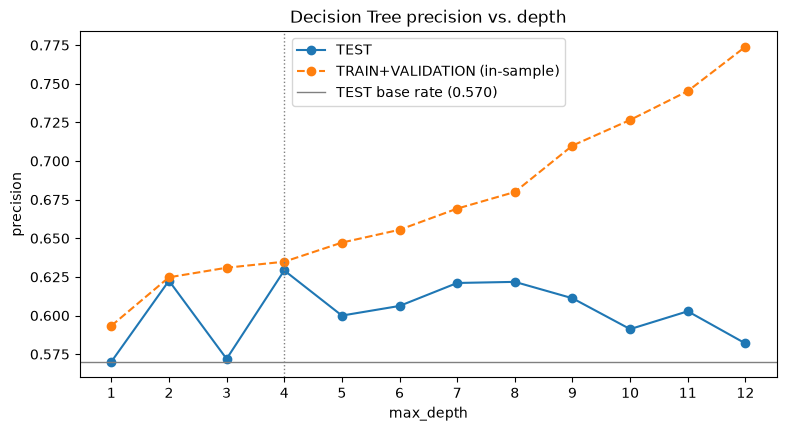

In [34]:
base_rate_test = y_test.mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(results.index, results['precision_test'], marker='o', label='TEST')
ax.plot(results.index, results['precision_train_val'], marker='o', linestyle='--', label='TRAIN+VALIDATION (in-sample)')
ax.axhline(base_rate_test, color='grey', linewidth=1, label=f'TEST base rate ({base_rate_test:.3f})')
ax.axvline(best_max_depth, color='grey', linestyle=':', linewidth=1)
ax.set_xlabel('max_depth')
ax.set_ylabel('precision')
ax.set_xticks(results.index)
ax.set_title('Decision Tree precision vs. depth')
ax.legend()
plt.show()

In [35]:
# Head of the best tree
print(export_text(models[best_max_depth], feature_names=list(X_train.columns), max_depth=3))

|--- cpi_core_yoy <= 0.02
|   |--- DGS10 <= 1.75
|   |   |--- DGS1 <= 0.56
|   |   |   |--- growth_snp500_90d <= 1.14
|   |   |   |   |--- class: 1
|   |   |   |--- growth_snp500_90d >  1.14
|   |   |   |   |--- class: 1
|   |   |--- DGS1 >  0.56
|   |   |   |--- growth_btc_usd_30d <= 1.07
|   |   |   |   |--- class: 0
|   |   |   |--- growth_btc_usd_30d >  1.07
|   |   |   |   |--- class: 1
|   |--- DGS10 >  1.75
|   |   |--- growth_wti_oil_365d <= 1.50
|   |   |   |--- Month_7 <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Month_7 >  0.50
|   |   |   |   |--- class: 0
|   |   |--- growth_wti_oil_365d >  1.50
|   |   |   |--- growth_wti_oil_30d <= 1.00
|   |   |   |   |--- class: 1
|   |   |   |--- growth_wti_oil_30d >  1.00
|   |   |   |   |--- class: 1
|--- cpi_core_yoy >  0.02
|   |--- FEDFUNDS <= 4.96
|   |   |--- growth_btc_usd_365d <= 1.21
|   |   |   |--- growth_dji_90d <= 0.96
|   |   |   |   |--- class: 1
|   |   |   |--- growth_dji_90d >  0.96
|   |   |   |   |--- cl

In [36]:
# Same data, same max_depth, same random_state -> refitting would give exactly this tree
clf_best = models[best_max_depth]
new_df['pred6_clf_best'] = clf_best.predict(X_all)

PREDICTIONS, IS_CORRECT = refresh_prediction_columns(new_df)
final_table = precision_table(new_df, PREDICTIONS)
final_table.round(4)

TEST: 33,163 rows, base rate (always predict 1) = 0.570


,positive_preds,coverage,precision,lift_vs_base_pp
prediction,,,,
pred0_manual_cci,921,0.0278,0.5646,-0.5489
pred1_manual_prev_g1,19158,0.5777,0.5787,0.8568
pred2_manual_prev_g1_and_snp,15244,0.4597,0.5726,0.2460
pred3_manual_dgs10_5,15910,0.4798,0.5877,1.7650
pred4_manual_dgs10_fedfunds,15921,0.4801,0.5025,-6.7549
pred5_clf_10,8628,0.2602,0.5912,2.1121
pred6_clf_best,6677,0.2013,0.6292,5.9082


### Optional: the clean protocol

The homework picks the depth by TEST precision and reports TEST precision for the same choice,
which is optimistic. The clean version (TODO 3 in the course notebook): fit on TRAIN only, pick the
depth on VALIDATION, look at TEST once. Set the flag to `True` to run it (about as long as the loop above).

In [37]:
RUN_CLEAN_PROTOCOL = False

if RUN_CLEAN_PROTOCOL:
    is_train = new_df.split == 'train'
    is_val = new_df.split == 'validation'
    clean = []
    for depth in range(1, 13):
        clf = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_all[is_train], y_all[is_train])
        clean.append({'max_depth': depth,
                      'precision_validation': precision_score(y_all[is_val], clf.predict(X_all[is_val]), zero_division=0),
                      'precision_test': precision_score(y_test, clf.predict(X_test), zero_division=0)})
    clean = pd.DataFrame(clean).set_index('max_depth')
    depth_by_val = int(clean['precision_validation'].idxmax())
    print(f"Depth chosen on VALIDATION: {depth_by_val}, its TEST precision: {clean.loc[depth_by_val, 'precision_test']:.4f}")
    display(clean.round(4))

## Q5 — [Exploratory] What data is missing?

The macro block is US-only (CPI, Fed funds, Treasury yields), while 21 of the 33 companies are European or Indian. In the course run the tree's most important features are slow macro variables (core CPI, Fed funds, 365-day growth of gold and oil), so the biggest gaps are regional and regime data:

1. **Local monetary policy and inflation**: ECB deposit facility rate (FRED: `ECBDFR`), euro-area HICP, RBI repo rate and India CPI. A rule on US rates cannot see an ECB or RBI cycle that diverges from the Fed.
2. **Currencies**: EUR/USD (FRED: `DEXUSEU`) and USD/INR (FRED: `DEXINUS`). Several tickers are US-listed shares of foreign companies (HDB, IBN, INFY, NVO, TTE), so their USD returns mix company performance with FX moves.
3. **Regional benchmarks**: Nifty 50 (`^NSEI`), Euro Stoxx 50 (`^STOXX50E`) and CAC 40 (`^FCHI`) from Yahoo Finance. Four tickers trade in Paris and eight on the NSE, but the data has only DAX, S&P 500, Dow Jones and the US-listed EPI ETF. Local indices would also allow relative strength: a stock's growth vs its own market.
4. **Market-wide risk sentiment**: VIX (FRED: `VIXCLS`) and India VIX. The data has each stock's own volatility, but no market fear gauge.
5. **Yield-curve spread as a ready feature**: 10Y minus 2Y (FRED: `T10Y2Y`) instead of separate yield levels; the inversion is the recession signal from Module 1.
6. **Earnings**: report dates and surprises (yfinance earnings dates), since a 30-day window often contains a report.

Some existing features need a transformation rather than new data: cumulative indicators (OBV, A/D line) trend over time and work as time stamps for the tree; their 30-day changes or z-scores would generalise better.

## Answers

In [38]:
pd.Series({
    'Q1: max |corr| of a month_wom dummy': f"{q1_answer:.3f} ({q1_dummy})",
    'Q2: precision of the best new hand rule (TEST)': f"{q2_answer:.3f} ({q2_rule})",
    'Q3: TEST rows where only pred5_clf_10 is correct': f"{q3_answer:,}",
    'Q4: optimal max_depth (1..12) by TEST precision': str(q4_answer),
}, name='answer').to_frame()

,answer
Q1: max |corr| of a month_wom dummy,0.025 (month_wom_October_w4)
Q2: precision of the best new hand rule (TEST),0.588 (pred3_manual_dgs10_5)
Q3: TEST rows where only pred5_clf_10 is correct,"1,243"
Q4: optimal max_depth (1..12) by TEST precision,4
